# 05 - Task 3: CNN encoder + LSTM decoder with attention

Read the 5 digits of an electricity meter from the 64 x 256 counter image prepared in notebook 04.

| Run | CNN encoder | Decoder |
|---|---|---|
| `meter_scratch_cnn_lstm_attention` | small CNN trained from scratch | LSTM + dot attention (short run, to check whether 800 images are enough) |
| `meter_mobilenet_lstm` | MobileNetV2 pretrained on ImageNet (transfer learning) | LSTM, no attention |
| `meter_mobilenet_lstm_attention` | MobileNetV2 pretrained on ImageNet (transfer learning) | LSTM + dot attention |

The last two models are identical except for the attention, as in Task 2. Settings are compared on the validation set (400 images); the test set (800 images) is used once, in notebook 06.

In [1]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
sys.path.insert(0, os.path.abspath(".."))

import keras
from keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIGURES_DIR, IMG_H, IMG_W, NUM_CLASSES, NUM_DIGITS, SEED
from src.meter_data import load_counters, make_augmenter
from src.metrics import meter_metrics
from src.training import load_history, load_trained, log_experiment, plot_history, train_model

FIG_DIR = FIGURES_DIR / "meter" / "learning_curves"
FIG_DIR.mkdir(parents=True, exist_ok=True)
%matplotlib inline

In [2]:
UNITS = 128          # số nơ-ron của mỗi chiều LSTM encoder (decoder có 2 x 128 = 256)
BATCH_SIZE = 32
SCRATCH_EPOCHS = 30  # model CNN tự xây: chạy cố định 30 epoch để xem có học được không
STAGE1_EPOCHS, STAGE1_LR = 40, 1e-3   # giai đoạn 1: đóng băng MobileNetV2, chỉ train phần mới
STAGE2_EPOCHS, STAGE2_LR = 150, 1e-4  # giai đoạn 2: mở băng MobileNetV2, learning rate nhỏ hơn 10 lần
CUT_LAYER = "block_13_expand_relu"    # lấy MobileNetV2 đến lớp này: ảnh 64 x 256 -> 4 x 16 x 576

# True: train lại model đó từ đầu; False: load model và lịch sử train đã lưu (train lại cả 3 model mất khoảng 3 giờ trên CPU)
TRAIN = {"meter_scratch_cnn_lstm_attention": False, "meter_mobilenet_lstm": False, "meter_mobilenet_lstm_attention": False}

## 1. Data

Images are kept as integers 0-255; the model itself rescales them and applies the augmentation of notebook 04 during training. The label of an image is its 5 digits, e.g. `07317` -> `[0, 7, 3, 1, 7]`, so the output of the model is a sequence of 5 classes out of 10.

In [3]:
data = load_counters()
x_train, y_train = data["x_train"], data["y_train"]
x_val, y_val = data["x_val"], data["y_val"]
print("train:", x_train.shape, y_train.shape, "| val:", x_val.shape, y_val.shape)

train: (800, 64, 256, 3) (800, 5) | val: (400, 64, 256, 3) (400, 5)


## 2. Model

The three models share the same sequence part; only the CNN encoder changes.

1. **CNN encoder (Chapter 5):** turns the 64 x 256 image into a 4 x 16 feature map. Each of the 16 columns describes a vertical strip of the counter about 16 pixels wide.
   - *From scratch:* four blocks of 3 x 3 convolution + batch normalisation + ReLU + 2 x 2 max pooling (32, 64, 128, 256 filters), as in the midterm project.
   - *Transfer learning (Chapter 4.3 and 5.3):* the first part of MobileNetV2 pretrained on ImageNet, cut at layer `block_13_expand_relu` (output 4 x 16 x 576). Training has two stages, as in our midterm Model 3: first the MobileNetV2 weights are frozen and only the new layers learn; then MobileNetV2 is unfrozen and everything is fine-tuned with a 10 times smaller learning rate (its batch-normalisation layers stay in inference mode).
2. **From image to sequence:** the 16 columns are read from left to right as a sequence of 16 steps (each step = one column, reduced to 128 values by a `Dense` layer).
3. **Encoder LSTM (Chapter 7):** a bidirectional LSTM reads the 16 columns in both directions and returns the 16 column states h_1 ... h_16 and its final states.
4. **Decoder LSTM (Chapter 8):** as in Task 2, the final encoder state is repeated 5 times (one per digit) and an LSTM initialised with the encoder's final states produces one state s_k per digit.
5. **Attention (Chapter 9):** each decoder state s_k is the query and the 16 column states are keys and values (dot-product score, `keras.layers.Attention`). Ideally the k-th digit gives most of its weight to the columns where the k-th digit is printed.
6. **Output:** `Dense(128, relu)`, dropout 0.3 and a softmax over the 10 digits for each of the 5 positions.

Loss: sparse categorical cross-entropy averaged over the 5 digits; optimizer Adam.

In [4]:
def scratch_encoder(x):
    # CNN tự xây: 4 khối Conv 3x3 - BatchNorm - ReLU - MaxPool 2x2 -> feature map 4 x 16 x 256
    x = layers.Rescaling(1.0 / 255, name="rescale")(x)
    for block, (filters, n_conv) in enumerate([(32, 1), (64, 1), (128, 2), (256, 2)], start=1):
        for j in range(n_conv):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"conv{block}_{j + 1}")(x)
            x = layers.BatchNormalization(name=f"bn{block}_{j + 1}")(x)
            x = layers.ReLU(name=f"relu{block}_{j + 1}")(x)
        x = layers.MaxPooling2D(2, name=f"pool{block}")(x)
    return x


def mobilenet_encoder():
    # phần đầu của MobileNetV2 (ImageNet), cắt tại CUT_LAYER -> feature map 4 x 16 x 576
    full = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_H, IMG_W, 3))
    return keras.Model(full.input, full.get_layer(CUT_LAYER).output, name="mobilenetv2_encoder")


def build_meter_model(encoder="mobilenet", attention=True, units=UNITS, learning_rate=STAGE1_LR):
    inputs = keras.Input(shape=(IMG_H, IMG_W, 3), name="counter_image")
    x = make_augmenter()(inputs)                      # chỉ có tác dụng khi train
    if encoder == "mobilenet":
        x = layers.Rescaling(1.0 / 127.5, offset=-1, name="rescale")(x)  # MobileNetV2 nhận ảnh trong [-1, 1]
        base = mobilenet_encoder()
        base.trainable = False                        # giai đoạn 1: đóng băng
        x = base(x, training=False)                   # BatchNorm của MobileNetV2 luôn ở chế độ suy luận
    else:
        x = scratch_encoder(x)

    # feature map (4, 16, C) -> chuỗi 16 cột từ trái sang phải, mỗi cột 4 x C giá trị
    x = layers.Permute((2, 1, 3), name="columns_first")(x)
    x = layers.Reshape((IMG_W // 16, (IMG_H // 16) * x.shape[-1]), name="to_sequence")(x)
    x = layers.Dense(units, activation="relu", name="column_features")(x)
    x = layers.Dropout(0.3, name="dropout_columns")(x)

    # Encoder: BiLSTM trả về trạng thái của cả 16 cột (cho attention) và trạng thái cuối của hai chiều
    enc_seq, fh, fc, bh, bc = layers.Bidirectional(
        layers.LSTM(units, return_sequences=True, return_state=True), name="encoder_bilstm")(x)
    state_h = layers.Concatenate(name="encoder_h")([fh, bh])
    state_c = layers.Concatenate(name="encoder_c")([fc, bc])

    # Decoder: một bước cho mỗi chữ số, khởi tạo bằng trạng thái cuối của encoder
    dec_in = layers.RepeatVector(NUM_DIGITS, name="repeat_context")(state_h)
    dec_seq = layers.LSTM(2 * units, return_sequences=True, name="decoder_lstm")(dec_in, initial_state=[state_h, state_c])

    y = dec_seq
    if attention:
        context = layers.Attention(name="attention")([dec_seq, enc_seq])   # query = s_k, key = value = 16 cột
        y = layers.Concatenate(name="concat_state_context")([dec_seq, context])

    y = layers.TimeDistributed(layers.Dense(128, activation="relu"), name="dense_hidden")(y)
    y = layers.Dropout(0.3, name="dropout_digits")(y)
    outputs = layers.TimeDistributed(layers.Dense(NUM_CLASSES, activation="softmax"), name="digits")(y)

    model = keras.Model(inputs, outputs, name=f"meter_{encoder}_lstm" + ("_attention" if attention else ""))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


build_meter_model("mobilenet", attention=True).summary()

C:\Users\duong\AppData\Local\Temp\ipykernel_13288\943588330.py:15: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  full = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_H, IMG_W, 3))


Model: "meter_mobilenet_lstm_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ counter_image       │ (None, 64, 256,   │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 64, 256,   │          0 │ counter_image[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale (Rescaling) │ (None, 64, 256,   │          0 │ augmentation[0][… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_encoder │ (None, 4, 16,     │    616,256 │ rescale[0][0]     │
│ (Functional)        │ 576)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ columns_first       │ (None, 16, 4,     │          0 │ mobilenetv2_enco… │
│ (Permute)           │ 576)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_sequence         │ (None, 16, 2304)  │          0 │ columns_first[0]… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ column_features     │ (None, 16, 128)   │    295,040 │ to_sequence[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_columns     │ (None, 16, 128)   │          0 │ column_features[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_bilstm      │ [(None, 16, 256), │    263,168 │ dropout_columns[… │
│ (Bidirectional)     │ (None, 128),      │            │                   │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_h           │ (None, 256)       │          0 │ encoder_bilstm[0… │
│ (Concatenate)       │                   │            │ encoder_bilstm[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 5, 256)    │          0 │ encoder_h[0][0]   │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_c           │ (None, 256)       │          0 │ encoder_bilstm[0… │
│ (Concatenate)       │                   │            │ encoder_bilstm[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ (None, 5, 256)    │    525,312 │ repeat_context[0… │
│                     │                   │            │ encoder_h[0][0],  │
│                     │                   │            │ encoder_c[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 5, 256)    │          0 │ decoder_lstm[0][… │
│ (Attention)         │                   │            │ encoder_bilstm[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_state_conte… │ (None, 5, 512)    │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,766,730 (6.74 MB)

 Trainable params: 1,150,474 (4.39 MB)

 Non-trainable params: 616,256 (2.35 MB)

## 3. Training

Same callbacks as in Task 2 (`ModelCheckpoint` on the validation loss, `EarlyStopping` that restores the best weights, `ReduceLROnPlateau`), with more patience because the validation set is small and noisier: 10 epochs in stage 1 and 15 epochs in stage 2 before stopping. Stage 2 may run up to 150 epochs: the fine-tuned model keeps improving slowly, so it is stopped by early stopping rather than by a fixed number of epochs.

### 3.1 CNN from scratch

A first attempt with the small CNN trained from scratch, run for a fixed 30 epochs.

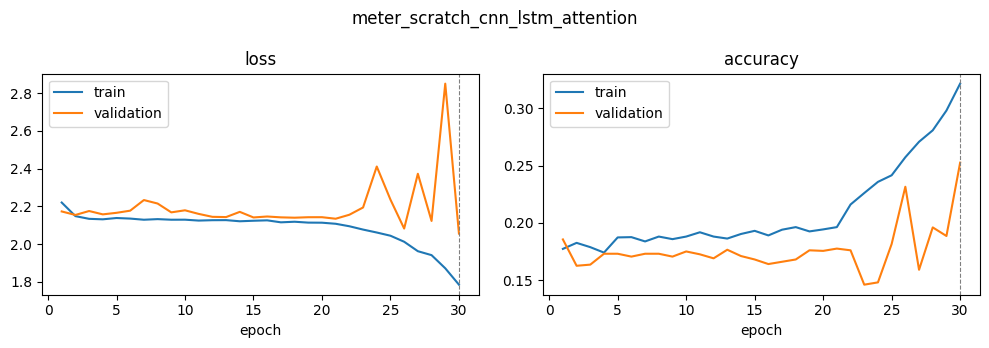

,epoch,accuracy,val_accuracy,val_loss
0,0,0.177,0.186,2.173
9,9,0.188,0.175,2.180
19,19,0.194,0.175,2.143
29,29,0.322,0.253,2.056


In [5]:
RUN_SCRATCH = "meter_scratch_cnn_lstm_attention"
if TRAIN[RUN_SCRATCH]:
    keras.utils.set_random_seed(SEED)
    model = build_meter_model("scratch", attention=True)
    # patience lớn hơn số epoch: chạy đủ 30 epoch để quan sát quá trình học
    history, minutes = train_model(model, RUN_SCRATCH, x_train, y_train, (x_val, y_val), SCRATCH_EPOCHS, BATCH_SIZE,
                                   patience=SCRATCH_EPOCHS, lr_patience=SCRATCH_EPOCHS)
    log_experiment({"run": RUN_SCRATCH, "task": "task3_meter", "encoder": "scratch CNN", "attention": "dot",
                    "max_epochs": SCRATCH_EPOCHS, "epochs_trained": len(history),
                    "best_epoch": int(history["val_loss"].idxmin()) + 1, "best_val_loss": round(history["val_loss"].min(), 6),
                    "train_minutes": round(minutes, 1), "params": model.count_params()})
history_scratch = load_history(RUN_SCRATCH)
fig = plot_history(history_scratch, RUN_SCRATCH, metric="accuracy")
fig.savefig(FIG_DIR / f"{RUN_SCRATCH}.png", dpi=150, bbox_inches="tight")
plt.show()
history_scratch[["epoch", "accuracy", "val_accuracy", "val_loss"]].iloc[[0, 9, 19, 29]].round(3)

For the first 20 epochs the digit accuracy stays at about 0.18-0.19 on both sets. This is exactly what a model gets by always predicting the most frequent digit of each position (a 0 for the first digit, right 45 % of the time, and 11-14 % for the other positions, 0.186 on average), so the network has not learned to read anything yet. From epoch 25 the training accuracy starts to rise (0.32 at epoch 30), but the validation accuracy stays between 0.17 and 0.25 and the validation loss jumps around: what the network learns from the 800 training images does not carry over to new images. Learning the visual features of digits from scratch needs more data than this dataset has, so the next models start from a CNN pretrained on a large image collection (ImageNet).

### 3.2 MobileNetV2 encoder (transfer learning), without and with attention

In [6]:
RUNS = {"meter_mobilenet_lstm": False, "meter_mobilenet_lstm_attention": True}


def train_two_stages(run, attention):
    keras.utils.set_random_seed(SEED)
    # giai đoạn 1: MobileNetV2 đóng băng, chỉ train các lớp mới
    model = build_meter_model("mobilenet", attention=attention, learning_rate=STAGE1_LR)
    h1, m1 = train_model(model, f"{run}_stage1", x_train, y_train, (x_val, y_val), STAGE1_EPOCHS, BATCH_SIZE,
                         patience=10, lr_patience=4)
    # giai đoạn 2: mở băng MobileNetV2 (BatchNorm vẫn ở chế độ suy luận), learning rate nhỏ hơn
    model.get_layer("mobilenetv2_encoder").trainable = True
    model.compile(optimizer=keras.optimizers.Adam(STAGE2_LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h2, m2 = train_model(model, run, x_train, y_train, (x_val, y_val), STAGE2_EPOCHS, BATCH_SIZE,
                         patience=15, lr_patience=5)
    log_experiment({"run": run, "task": "task3_meter", "encoder": "MobileNetV2 (ImageNet)",
                    "attention": "dot" if attention else "none", "max_epochs": f"{STAGE1_EPOCHS} + {STAGE2_EPOCHS}",
                    "epochs_trained": f"{len(h1)} + {len(h2)}", "best_epoch": int(h2["val_loss"].idxmin()) + 1,
                    "best_val_loss": round(h2["val_loss"].min(), 6), "train_minutes": round(m1 + m2, 1),
                    "params": model.count_params()})


histories = {}
for run, attention in RUNS.items():
    if TRAIN[run]:
        train_two_stages(run, attention)
    # lịch sử của hai giai đoạn nối tiếp nhau
    histories[run] = pd.concat([load_history(f"{run}_stage1"), load_history(run)], ignore_index=True)

C:\Users\duong\AppData\Local\Temp\ipykernel_13288\943588330.py:15: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  full = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_H, IMG_W, 3))


Epoch 1/40
25/25 - 25s - 1s/step - accuracy: 0.1810 - loss: 2.2054 - val_accuracy: 0.1830 - val_loss: 2.1722 - learning_rate: 1.0000e-03
Epoch 2/40
25/25 - 7s - 295ms/step - accuracy: 0.2002 - loss: 2.1237 - val_accuracy: 0.2130 - val_loss: 2.1171 - learning_rate: 1.0000e-03
Epoch 3/40
25/25 - 7s - 294ms/step - accuracy: 0.2423 - loss: 2.0458 - val_accuracy: 0.2490 - val_loss: 2.0053 - learning_rate: 1.0000e-03
Epoch 4/40
25/25 - 8s - 302ms/step - accuracy: 0.2873 - loss: 1.9236 - val_accuracy: 0.3300 - val_loss: 1.8277 - learning_rate: 1.0000e-03
Epoch 5/40
25/25 - 7s - 299ms/step - accuracy: 0.3635 - loss: 1.7048 - val_accuracy: 0.4505 - val_loss: 1.4955 - learning_rate: 1.0000e-03
Epoch 6/40
25/25 - 7s - 296ms/step - accuracy: 0.4793 - loss: 1.3940 - val_accuracy: 0.5720 - val_loss: 1.1558 - learning_rate: 1.0000e-03
Epoch 7/40
25/25 - 7s - 294ms/step - accuracy: 0.5638 - loss: 1.1425 - val_accuracy: 0.6420 - val_loss: 0.9740 - learning_rate: 1.0000e-03
Epoch 8/40
25/25 - 8s - 303ms

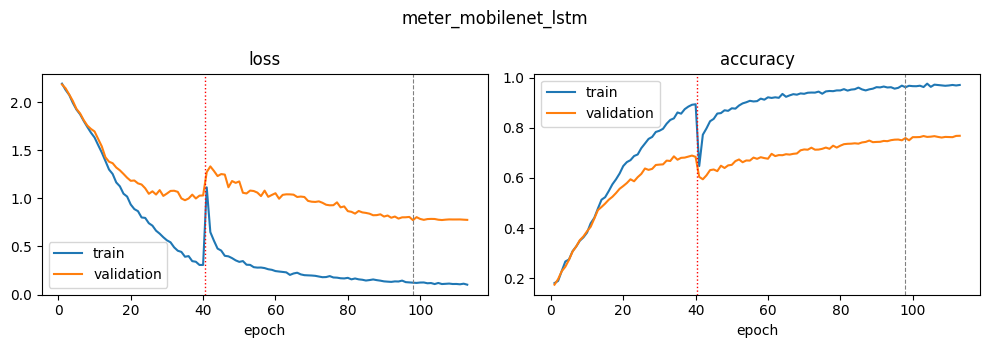

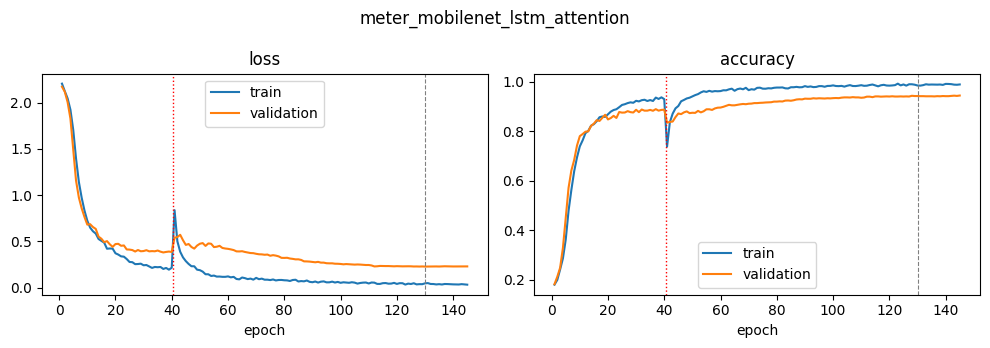

In [7]:
for run, history in histories.items():
    fig = plot_history(history, run, metric="accuracy")
    stage1_len = len(load_history(f"{run}_stage1"))
    for ax in fig.axes:
        ax.axvline(stage1_len + 0.5, color="red", ls=":", lw=1)  # ranh giới giai đoạn 1 / giai đoạn 2
    fig.savefig(FIG_DIR / f"{run}.png", dpi=150, bbox_inches="tight")
    plt.show()

- In stage 1 (frozen MobileNetV2) the attention model learns much faster: its validation digit accuracy reaches 0.89 (best epoch 37), against 0.67 for the model without attention (best epoch 35).
- At the start of stage 2 (red dotted line) both curves jump: for a few epochs the loss rises, because unfreezing MobileNetV2 suddenly lets the gradients change the pretrained features and the optimizer starts again with a new state. After about 5 epochs the models recover and improve beyond stage 1.
- Fine-tuning improves both models: the validation digit accuracy goes from 0.67 to 0.76 without attention (early stopping at stage-2 epoch 73, best epoch 58) and from 0.89 to 0.94 with attention (stopped at epoch 105, best epoch 90).
- Without attention the gap between training and validation accuracy is large (0.96 against 0.76 at the best epoch): the model largely memorises the training images. With attention the gap is much smaller (0.985 against 0.94).

## 4. Validation results

`accuracy` in the training log is the share of correct digits. A meter is only read correctly if all 5 digits are right, so the validation images are also evaluated with the full-reading accuracy and with R², NSE, MAE and RMSE of the reading value in kWh (`meter_metrics` in `src/metrics.py`).

In [8]:
all_runs = [RUN_SCRATCH] + list(RUNS)
models = {run: load_trained(run) for run in all_runs}
val_results = {}
for run, model in models.items():
    pred = model.predict(x_val, verbose=0).argmax(axis=-1)
    val_results[run] = meter_metrics(y_val, pred)
results = pd.DataFrame(val_results).T
results["params"] = [m.count_params() for m in models.values()]
results.round(4)

,digit_accuracy,reading_accuracy,R2,NSE,MAE,RMSE,params
meter_scratch_cnn_lstm_attention,0.2525,0.0025,0.0345,-0.1116,10484.3300,17947.6396,2115306
meter_mobilenet_lstm,0.7590,0.2950,0.5175,0.4885,3836.1250,12174.5570,1733962
meter_mobilenet_lstm_attention,0.9425,0.7800,0.8622,0.8590,1241.1925,6392.7203,1766730


- The CNN trained from scratch has not learned to read: only 1 of the 400 validation meters (0.25 %) is read correctly, and its NSE is negative, i.e. it is worse than always predicting the mean reading.
- Transfer learning makes the task learnable, but without attention only 29.5 % of the meters are read completely right (75.9 % of the digits).
- With attention the share of correctly read meters rises to 78.0 % (94.3 % of the digits), and the reading value reaches R² 0.86 and NSE 0.86 (MAE 1,241 kWh). Unlike in Task 2, attention makes a large difference here: each digit is printed at a different place in the image, and the attention lets the decoder look at that place (see the attention maps in notebook 06).

The attention model is used as the main model in notebook 06.